# 02 · Exploratory Data Analysis

**Goal:** understand traffic, the overall funnel, and which dimensions (device, channel,
speed, time, customer type) are worth a deep-dive. EDA here is about **forming hypotheses**;
Notebook 03 (SQL) and 04 (A/B test) test them.

Period: **1 Aug – 30 Oct 2026** (91 days) · Human sessions only (bots removed in notebook 01).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, IMG = ROOT / "data" / "processed", ROOT / "images"
IMG.mkdir(exist_ok=True)

f = pd.read_parquet(PROC / "session_funnel.parquet")
o = pd.read_parquet(PROC / "orders_clean.parquet")

sns.set_theme(style="whitegrid", font_scale=1.0)
BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
STAGES = ["reached_session", "product_view", "add_to_cart", "checkout_start", "payment_attempt", "purchase"]
LABELS = ["Session", "Product view", "Add to cart", "Checkout start", "Payment attempt", "Purchase"]

def save(fig, name):
    fig.savefig(IMG / name, dpi=150, bbox_inches="tight")

## 1 · Headline KPIs

In [2]:
kpi = {
    "Sessions": len(f),
    "Unique users": f.user_id.nunique(),
    "Orders": int(f.purchase.sum()),
    "Conversion rate (orders / sessions)": f"{100 * f.purchase.mean():.2f}%",
    "Revenue (net, ₹)": f"{o.net_value_inr.sum():,.0f}",
    "Average order value (₹)": f"{o.net_value_inr.mean():,.0f}",
    "Cart abandonment rate": f"{100 * (1 - f.purchase.sum() / f.add_to_cart.sum()):.1f}%",
    "Revenue per session (₹)": f"{o.net_value_inr.sum() / len(f):.2f}",
}
pd.Series(kpi).to_frame("value")

,value
Sessions,80000
Unique users,32305
Orders,2734
Conversion rate (orders / sessions),3.42%
"Revenue (net, ₹)","4,483,548"
Average order value (₹),"1,640"
Cart abandonment rate,67.9%
Revenue per session (₹),56.04


## 2 · The overall funnel — where do we lose people?

In [3]:
counts = f[STAGES].sum().values
step = np.r_[1, counts[1:] / counts[:-1]]
overall = counts / counts[0]
funnel_tbl = pd.DataFrame({"stage": LABELS, "sessions": counts,
                           "step_conversion_%": (100 * step).round(1),
                           "of_all_sessions_%": (100 * overall).round(2),
                           "lost_at_this_step": np.r_[0, -np.diff(counts)]})
funnel_tbl

,stage,sessions,step_conversion_%,of_all_sessions_%,lost_at_this_step
0,Session,80000,100.0,100.00,0
1,Product view,56002,70.0,70.00,23998
2,Add to cart,8523,15.2,10.65,47479
3,Checkout start,4676,54.9,5.85,3847
4,Payment attempt,3120,66.7,3.90,1556
5,Purchase,2734,87.6,3.42,386


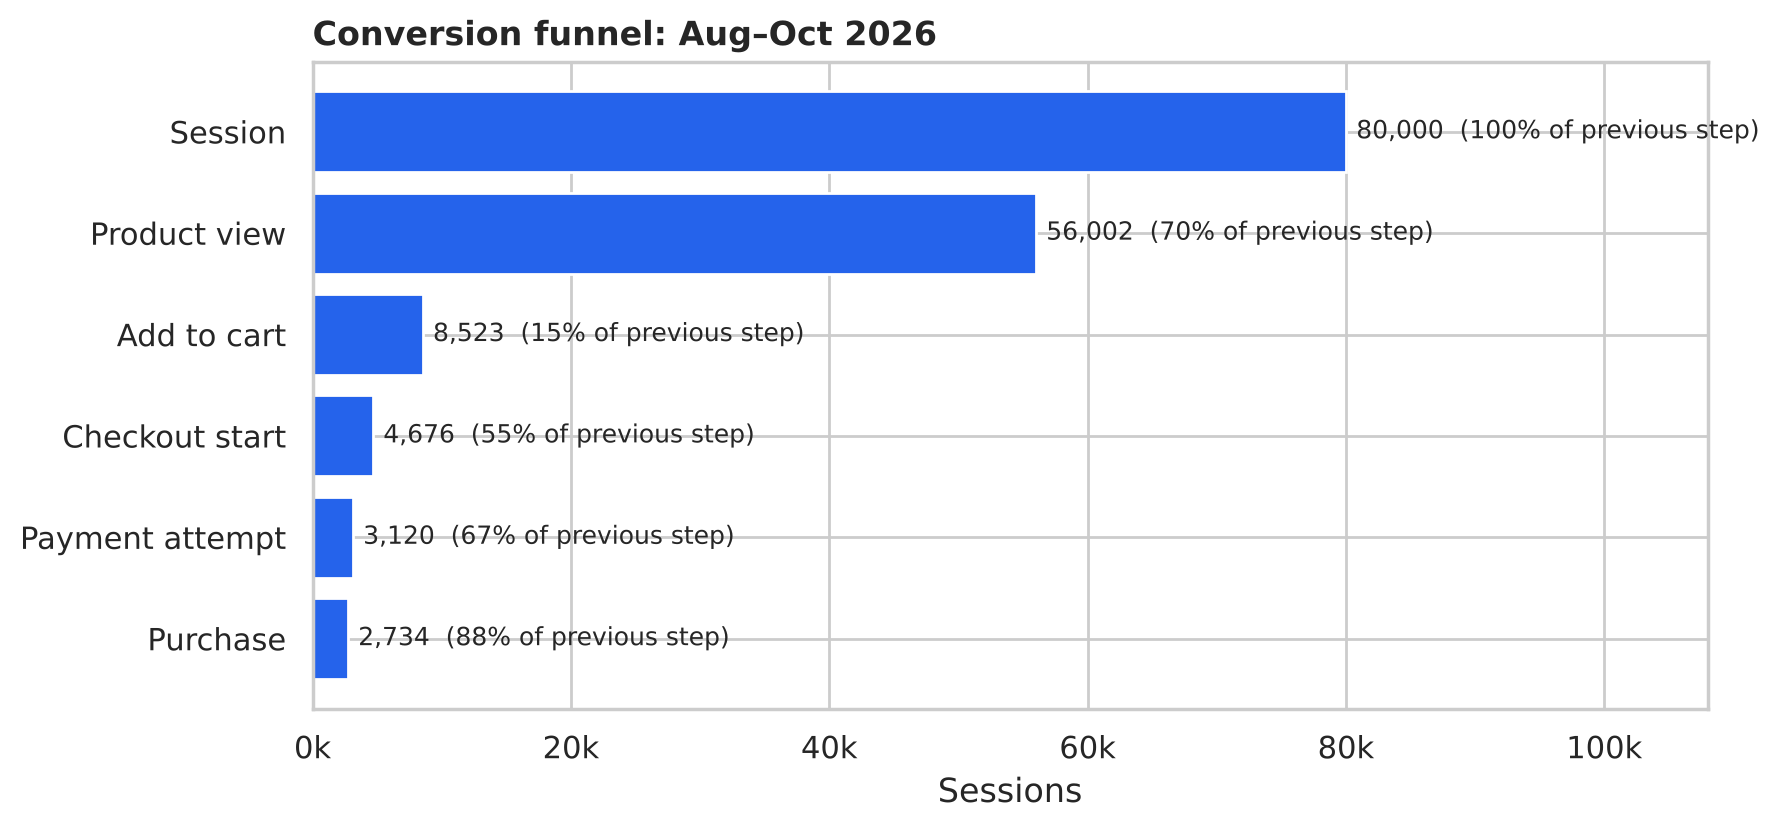

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(LABELS[::-1], counts[::-1], color=[BLUE] * 6)
for b, c, sc in zip(bars, counts[::-1], step[::-1]):
    ax.text(b.get_width() + counts[0] * 0.01, b.get_y() + b.get_height() / 2,
            f"{c:,}  ({sc:.0%} of previous step)", va="center", fontsize=9)
ax.set_xlim(0, counts[0] * 1.35); ax.set_xlabel("Sessions")
ax.set_title("Conversion funnel: Aug–Oct 2026", loc="left", fontweight="bold")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
save(fig, "01_overall_funnel.png"); plt.show()

**Observations**
* The **biggest absolute leak is Product view → Add to cart**: only ~15% of product viewers add anything.
  That's a product-page / merchandising problem (price, images, reviews, delivery promise).
* **Add to cart → Checkout start** loses about half of carts, and **Checkout → Payment** loses about a third.
  These are lower-volume steps but the users are *high intent*, so each recovered user is worth more.
* Payment success (attempt → purchase) is high (~88%), so payments are **not** the main problem overall.

## 3 · Traffic trend

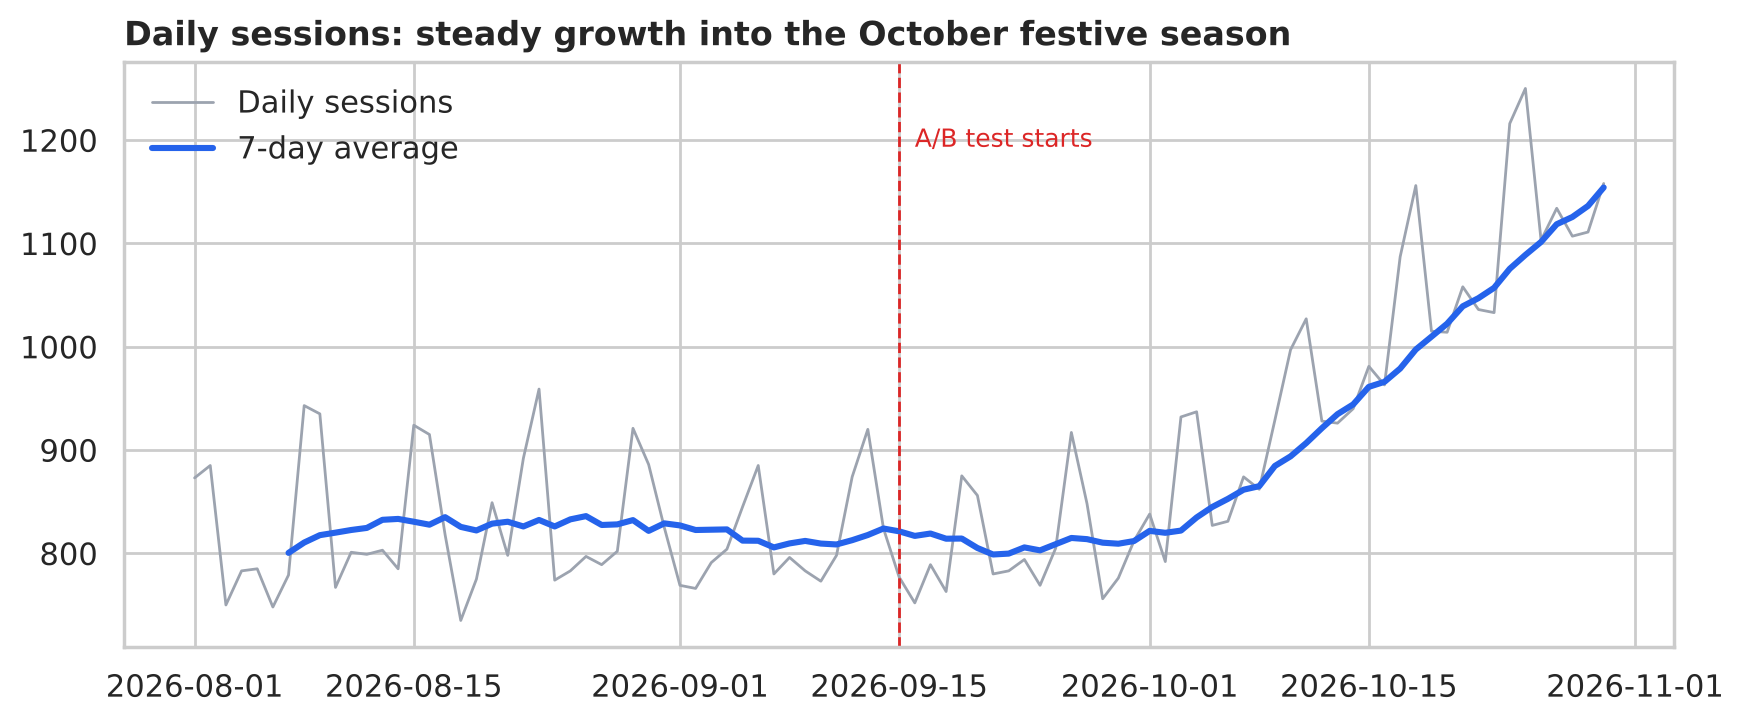

In [5]:
daily = f.set_index(pd.to_datetime(f.session_start)).resample("D").agg(
    sessions=("session_id", "count"), orders=("purchase", "sum"))
daily["cvr"] = daily.orders / daily.sessions

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(daily.index, daily.sessions, color=GREY, lw=1, label="Daily sessions")
ax.plot(daily.index, daily.sessions.rolling(7).mean(), color=BLUE, lw=2.2, label="7-day average")
ax.axvline(pd.Timestamp("2026-09-15"), color=RED, ls="--", lw=1)
ax.text(pd.Timestamp("2026-09-16"), ax.get_ylim()[1] * 0.95, "A/B test starts", color=RED, fontsize=9, va="top")
ax.set_title("Daily sessions: steady growth into the October festive season", loc="left", fontweight="bold")
ax.legend(loc="upper left", frameon=False)
save(fig, "02_daily_traffic.png"); plt.show()

Sessions climb through October (festive season), with higher traffic at weekends.
**Conversion rate also rises month on month** (table below). Two likely drivers: returning visitors
(who convert better) become a bigger share over time, and the checkout experiment started mid-September.
We separate these effects properly in Notebook 04 instead of crediting all of it to the experiment.

In [6]:
daily.resample("MS").agg({"sessions": "sum", "orders": "sum"}).assign(
    cvr_pct=lambda d: (100 * d.orders / d.sessions).round(2))

,sessions,orders,cvr_pct
session_start,,,
2026-08-01,25678,725,2.82
2026-09-01,24260,847,3.49
2026-10-01,30062,1162,3.87


## 4 · Device: mobile is two-thirds of traffic but converts worst

In [7]:
by_dev = f[f.device != "unknown"].groupby("device").agg(
    sessions=("session_id", "count"), orders=("purchase", "sum"),
    carts=("add_to_cart", "sum"), checkouts=("checkout_start", "sum"),
    payments=("payment_attempt", "sum"), avg_load_ms=("page_load_ms", "median"))
by_dev["share_of_traffic_%"] = (100 * by_dev.sessions / by_dev.sessions.sum()).round(1)
by_dev["cvr_%"] = (100 * by_dev.orders / by_dev.sessions).round(2)
by_dev["cart_to_checkout_%"] = (100 * by_dev.checkouts / by_dev.carts).round(1)
by_dev["checkout_to_payment_%"] = (100 * by_dev.payments / by_dev.checkouts).round(1)
by_dev.sort_values("sessions", ascending=False)

,sessions,orders,carts,checkouts,payments,avg_load_ms,share_of_traffic_%,cvr_%,cart_to_checkout_%,checkout_to_payment_%
device,,,,,,,,,,
mobile,53941,1533,5546,2772,1739,2536.0,68.2,2.84,50.0,62.7
desktop,20432,980,2352,1538,1125,1648.0,25.8,4.80,65.4,73.1
tablet,4682,188,514,305,216,2199.0,5.9,4.02,59.3,70.8


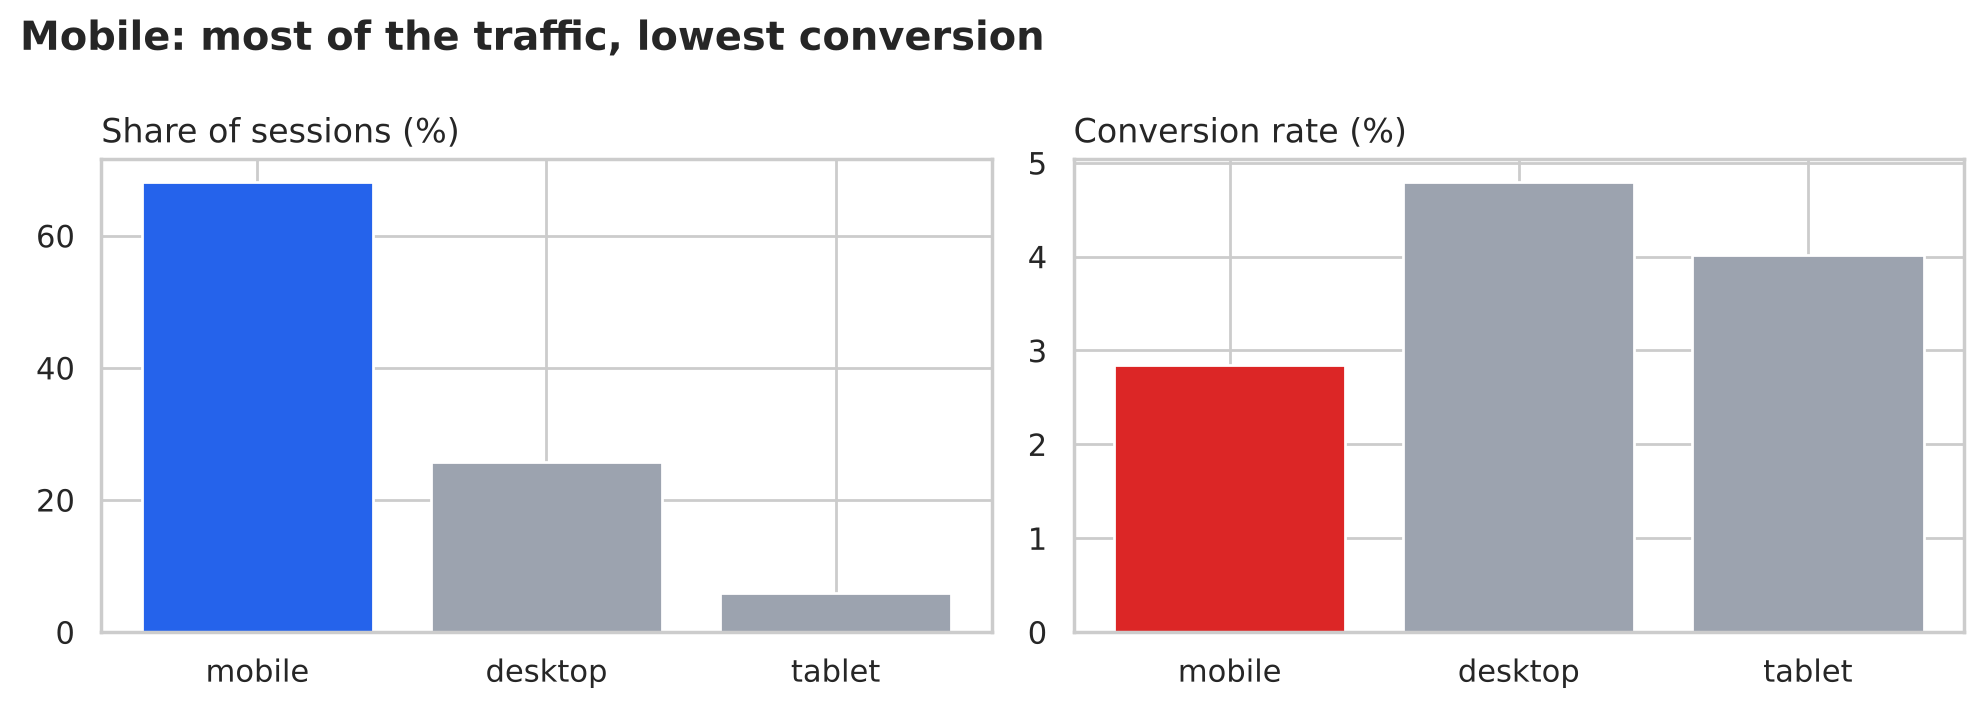

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
d = by_dev.sort_values("sessions", ascending=False)
ax[0].bar(d.index, d["share_of_traffic_%"], color=[BLUE, GREY, GREY]); ax[0].set_title("Share of sessions (%)", loc="left")
ax[1].bar(d.index, d["cvr_%"], color=[RED, GREY, GREY]); ax[1].set_title("Conversion rate (%)", loc="left")
fig.suptitle("Mobile: most of the traffic, lowest conversion", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_device.png"); plt.show()

The gap opens **after** the cart: mobile users add to cart at a similar rate but drop sharply at
*cart → checkout* and *checkout → payment*. That points at the **mobile checkout experience**,
which is exactly what the one-page-checkout experiment (from 15 Sep) targets.

## 5 · Channel: volume vs quality

In [9]:
by_ch = f.groupby("channel").agg(sessions=("session_id", "count"), orders=("purchase", "sum"),
                                  revenue=("revenue_inr", "sum"), views=("product_view", "mean"))
by_ch["cvr_%"] = (100 * by_ch.orders / by_ch.sessions).round(2)
by_ch["product_view_rate_%"] = (100 * by_ch.views).round(1)
by_ch["revenue_per_session_₹"] = (by_ch.revenue / by_ch.sessions).round(1)
by_ch = by_ch.drop(columns="views").sort_values("sessions", ascending=False)
by_ch

,sessions,orders,revenue,cvr_%,product_view_rate_%,revenue_per_session_₹
channel,,,,,,
organic_search,21691,793,1294644.22,3.66,73.2,59.7
paid_social,17687,359,554523.38,2.03,55.7,31.4
paid_search,14542,585,1003267.19,4.02,75.9,69.0
direct,11898,469,805493.14,3.94,75.2,67.7
email,6209,310,481097.88,4.99,82.8,77.5
affiliate,3988,111,172407.72,2.78,62.5,43.2
referral,3985,107,172114.62,2.69,66.1,43.2


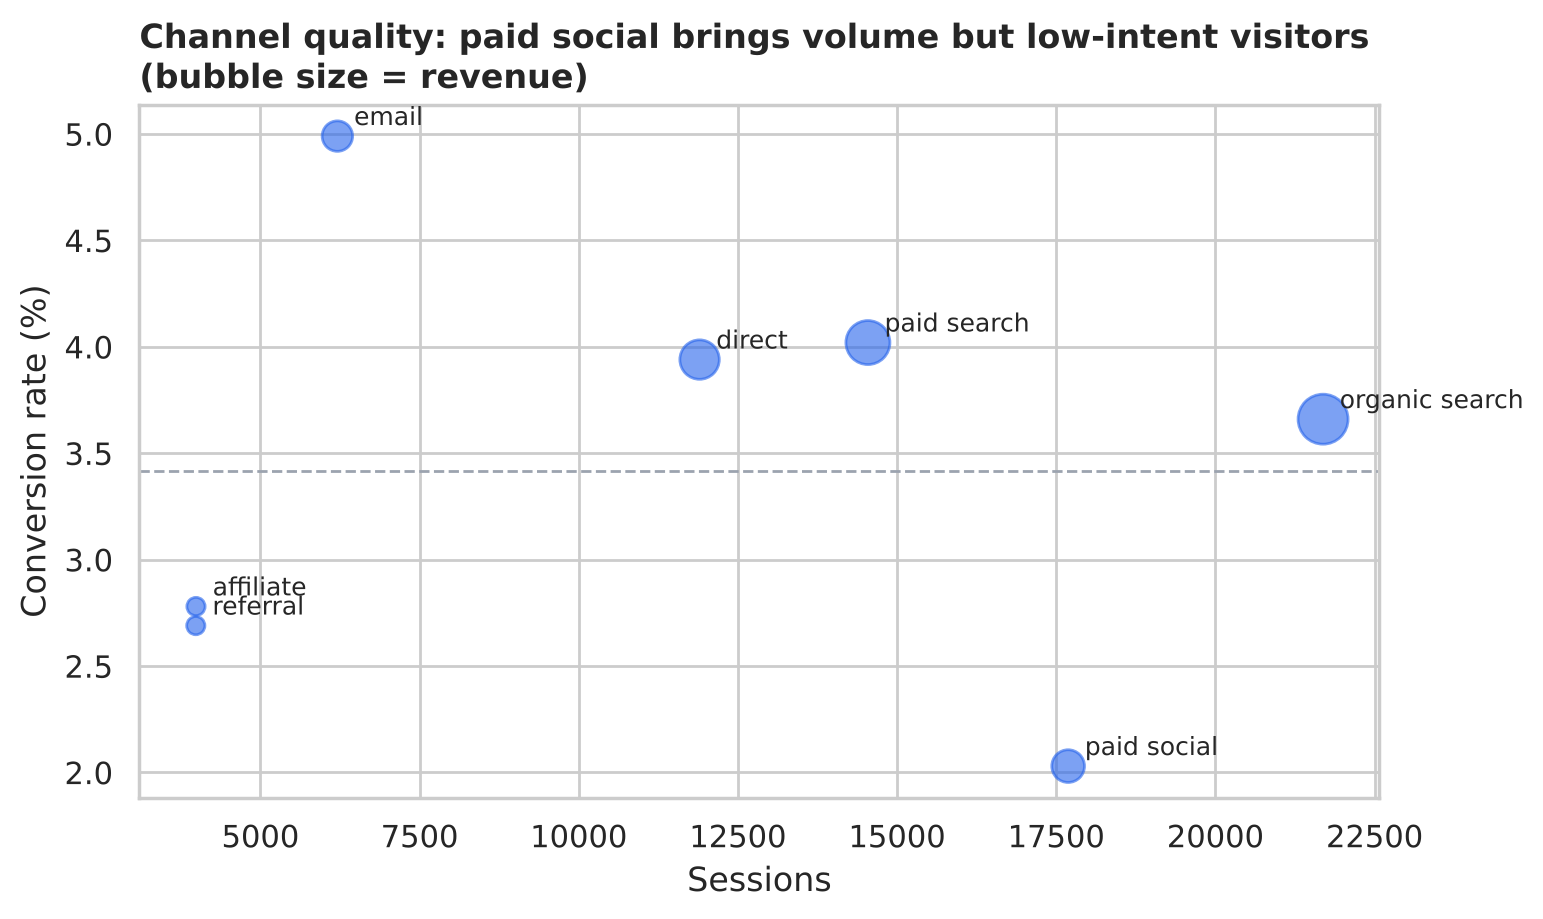

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(by_ch.sessions, by_ch["cvr_%"], s=by_ch.revenue / 4000, color=BLUE, alpha=.6)
for ch, r in by_ch.iterrows():
    ax.annotate(ch.replace("_", " "), (r.sessions, r["cvr_%"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.axhline(100 * f.purchase.mean(), color=GREY, ls="--", lw=1)
ax.set_xlabel("Sessions"); ax.set_ylabel("Conversion rate (%)")
ax.set_title("Channel quality: paid social brings volume but low-intent visitors\n(bubble size = revenue)",
             loc="left", fontweight="bold")
save(fig, "04_channel_quality.png"); plt.show()

* **Paid social** is the 2nd-largest channel but converts about **40% below** the site average. Many
  visitors never even view a product → a landing-page / audience-targeting issue.
* **Email** and **direct** are small but convert best (returning, high-intent users).
* Hypothesis for later: shift some paid-social budget toward paid search / retargeting, and fix the
  paid-social landing pages.

## 6 · Page speed: slow pages lose carts

In [11]:
bins = [0, 1500, 2000, 2500, 3000, 4000, 1e9]
lbl = ["<1.5s", "1.5–2s", "2–2.5s", "2.5–3s", "3–4s", ">4s"]
f["load_bucket"] = pd.cut(f.page_load_ms, bins=bins, labels=lbl)
spd = f.groupby("load_bucket", observed=True).agg(sessions=("session_id", "count"),
                                                  atc_rate=("add_to_cart", "mean"), cvr=("purchase", "mean"))
spd[["atc_rate", "cvr"]] = (100 * spd[["atc_rate", "cvr"]]).round(2)
spd

,sessions,atc_rate,cvr
load_bucket,,,
<1.5s,14144,11.86,4.39
1.5–2s,17025,11.87,3.81
2–2.5s,15961,11.90,3.90
2.5–3s,12445,11.87,3.60
3–4s,13128,6.89,1.93
>4s,7297,7.47,1.92


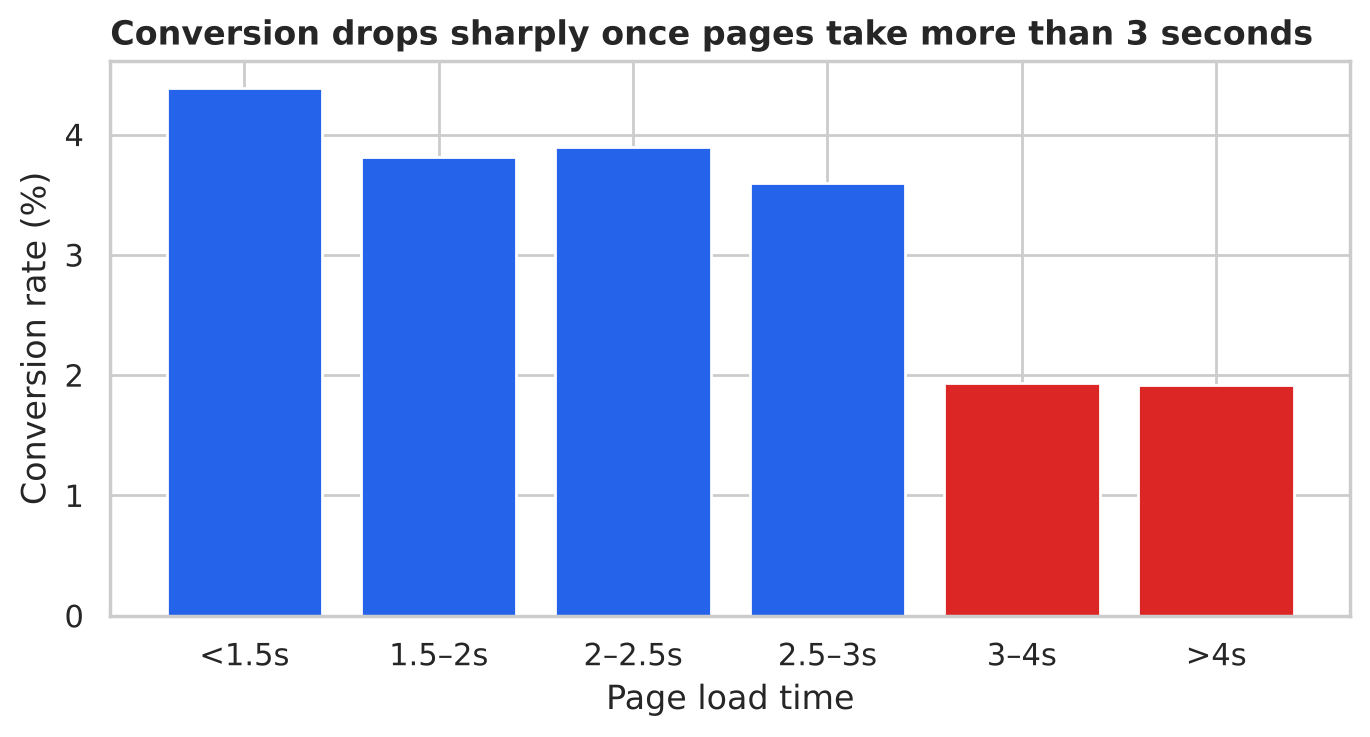

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(spd.index.astype(str), spd.cvr, color=[BLUE] * 4 + [RED] * 2)
ax.set_ylabel("Conversion rate (%)"); ax.set_xlabel("Page load time")
ax.set_title("Conversion drops sharply once pages take more than 3 seconds", loc="left", fontweight="bold")
save(fig, "05_page_speed.png"); plt.show()

In [13]:
slow_share = (f.page_load_ms > 3000).groupby(f.device).mean().mul(100).round(1)
slow_share.to_frame("% of sessions slower than 3s")

,% of sessions slower than 3s
device,
desktop,6.6
mobile,33.1
tablet,21.4
unknown,25.8


Above 3 s, add-to-cart and conversion both **roughly halve**. Slow sessions are mostly **mobile in tier-2/3 cities**,
so speed is part of the mobile story too. (Correlation ≠ causation; a speed A/B test would confirm it.)

## 7 · When do people shop?

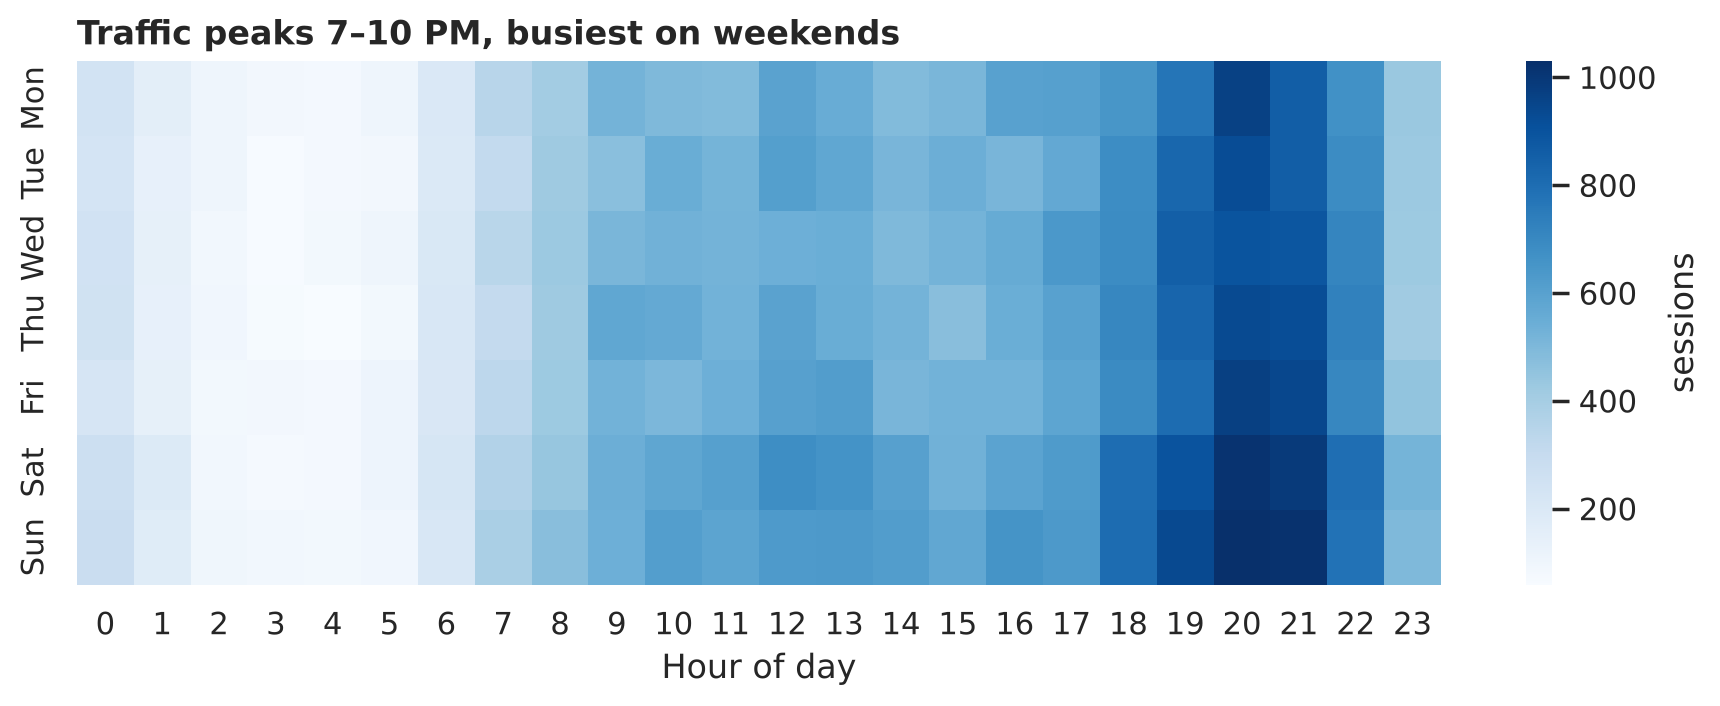

In [14]:
f["hour"] = pd.to_datetime(f.session_start).dt.hour
f["dow"] = pd.to_datetime(f.session_start).dt.day_name().str[:3]
order_days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = f.pivot_table(index="dow", columns="hour", values="session_id", aggfunc="count").reindex(order_days)
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "sessions"})
ax.set_title("Traffic peaks 7–10 PM, busiest on weekends", loc="left", fontweight="bold"); ax.set_xlabel("Hour of day"); ax.set_ylabel("")
save(fig, "06_traffic_heatmap.png"); plt.show()

Use: schedule email/push campaigns and flash sales for **7–10 PM**, and avoid deploying site
changes in that window.

## 8 · New vs returning visitors

In [15]:
nr = f.groupby("is_returning").agg(sessions=("session_id", "count"), cvr=("purchase", "mean"),
                                    atc=("add_to_cart", "mean"), rps=("revenue_inr", "mean"))
nr.index = ["new", "returning"]
nr[["cvr", "atc"]] = (100 * nr[["cvr", "atc"]]).round(2); nr["rps"] = nr.rps.round(1)
nr.rename(columns={"cvr": "cvr_%", "atc": "add_to_cart_%", "rps": "revenue_per_session_₹"})

,sessions,cvr_%,add_to_cart_%,revenue_per_session_₹
new,32305,2.45,8.51,42.4
returning,47695,4.07,12.10,65.3


## 9 · Orders: value, category and payment method

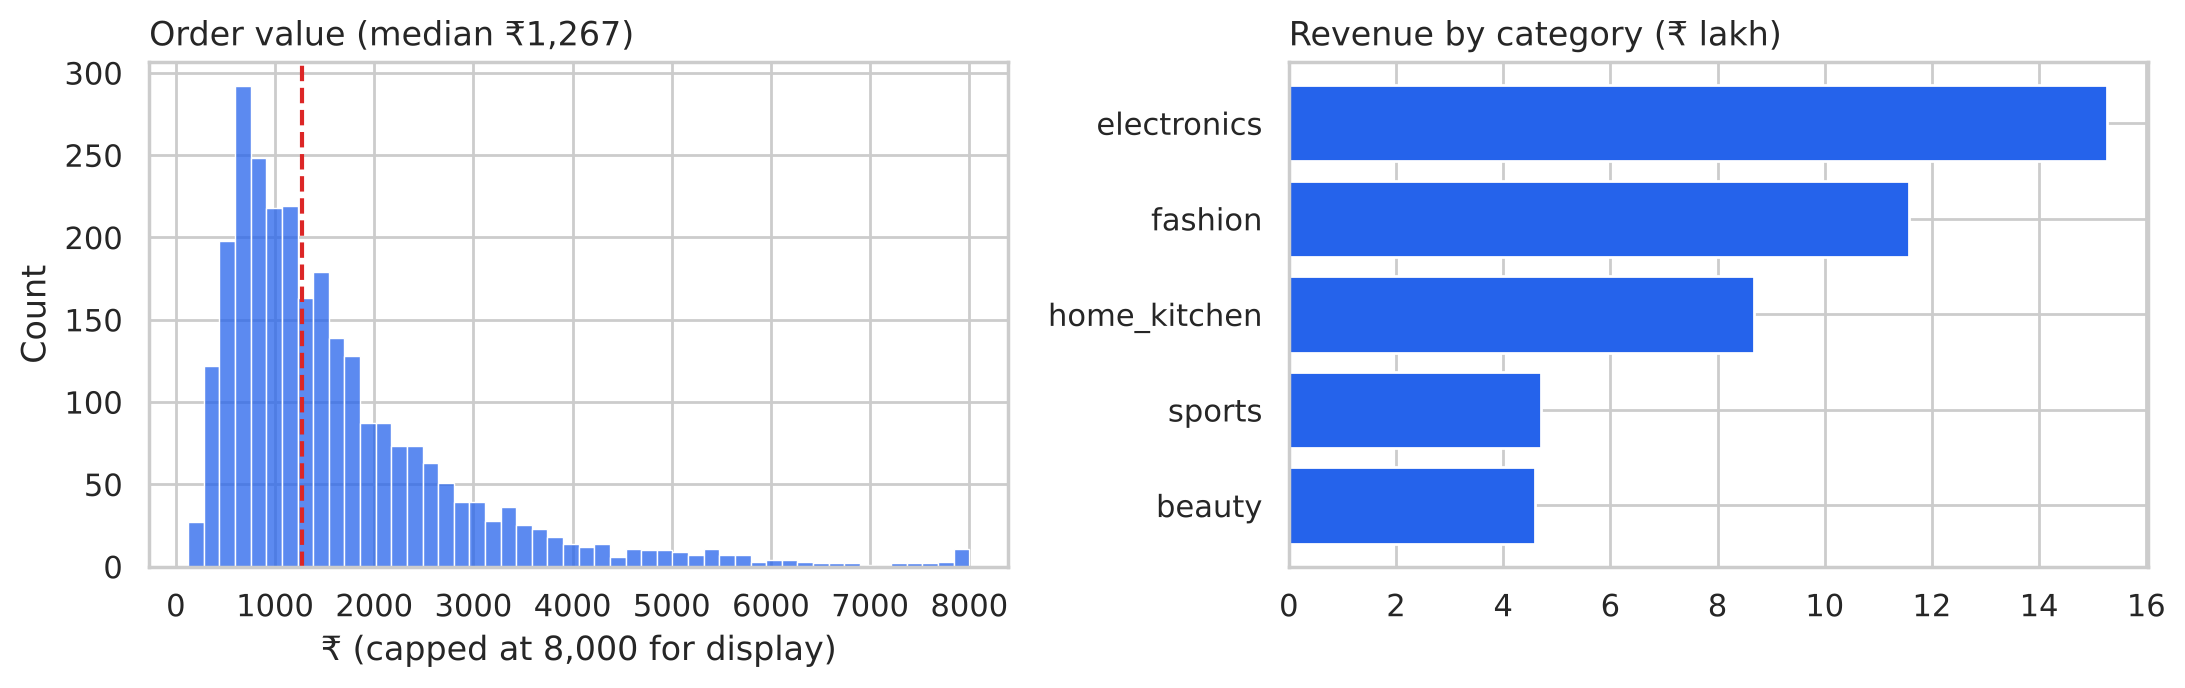

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(o.net_value_inr.clip(upper=8000), bins=50, color=BLUE, ax=ax[0])
ax[0].axvline(o.net_value_inr.median(), color=RED, ls="--"); ax[0].set_title(f"Order value (median ₹{o.net_value_inr.median():,.0f})", loc="left")
ax[0].set_xlabel("₹ (capped at 8,000 for display)")
cat = o.groupby("product_category").net_value_inr.agg(["count", "sum", "mean"]).sort_values("sum")
ax[1].barh(cat.index, cat["sum"] / 1e5, color=BLUE); ax[1].set_title("Revenue by category (₹ lakh)", loc="left")
fig.tight_layout(); save(fig, "07_orders.png"); plt.show()

In [17]:
pay = (pd.read_parquet(PROC / "events_clean.parquet")
         .query("event_name in ['payment_attempt','purchase']")
         .pivot_table(index="payment_method", columns="event_name", values="session_id", aggfunc="nunique"))
pay["success_rate_%"] = (100 * pay.purchase / pay.payment_attempt).round(1)
pay["share_of_attempts_%"] = (100 * pay.payment_attempt / pay.payment_attempt.sum()).round(1)
pay.sort_values("payment_attempt", ascending=False)

event_name,payment_attempt,purchase,success_rate_%,share_of_attempts_%
payment_method,,,,
upi,1679,1502,89.5,53.8
card,816,652,79.9,26.2
cod,466,442,94.8,14.9
wallet,159,138,86.8,5.1


**Card payments fail ~1 in 5 times**, vs ~1 in 10 for UPI. Cards are a quarter of attempts, so
better card routing / saved cards / nudging card users to UPI is a cheap win to explore.

## 10 · Hypotheses to test next (Notebook 03 & 04)
| # | Hypothesis | Evidence so far | How we'll test it |
|---|---|---|---|
| H1 | Mobile checkout is the biggest *fixable* leak | Mobile cart→checkout and checkout→payment well below desktop | Segment funnel in SQL (03) |
| H2 | One-page checkout improves mobile conversion | Launched 15 Sep, 50/50 split | A/B test with significance + CI (04) |
| H3 | Paid social traffic is low-intent | CVR ~40% below site average, low product-view rate | Channel funnel + revenue/session (03) |
| H4 | Slow pages (>3s) cost conversions | CVR roughly halves above 3s | Speed × device breakdown (03) |
| H5 | Card payment failures lose revenue | ~20% card failure vs ~10% UPI | Lost-revenue estimate (03) |